## Case Study 3: E-Commerce Customer Segmentation

**Objective:** The aim of this project is to analyze customer purchasing behaviour using RFM (Recency, Frequency, Monetary) analysis and identify customer segments using **K-Means and DBSCAN clustering**. PCA and t-SNE are used for visualization, and clustering results are evaluated to suggest effective marketing strategies.

**Tools Used:** Python, Pandas, NumPy, Scikit-learn, Matplotlib, Seaborn and Google Colab.


In [73]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [74]:
df = pd.read_csv('/content/Dataset.csv', encoding='latin1')

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [75]:
print("Dataset Shape:", df.shape)
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Dataset Shape: (541909, 8)
Total Rows: 541909
Total Columns: 8


In [76]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [77]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [78]:
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 5268


In [79]:
df.describe()

,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [80]:
print(df.columns.tolist())

['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [81]:
df = df.dropna(subset=['CustomerID', 'InvoiceDate',
                       'Quantity', 'UnitPrice'])

print("Shape after removing missing values:", df.shape)

Shape after removing missing values: (406829, 8)


In [82]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (401604, 8)


In [83]:
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]

df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]

print("Shape after cleaning:", df.shape)

Shape after cleaning: (392692, 8)


In [84]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

print(df['InvoiceDate'].dtype)

datetime64[ns]


In [85]:
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [86]:
print("Minimum Date:", df['InvoiceDate'].min())
print("Maximum Date:", df['InvoiceDate'].max())

Minimum Date: 2010-12-01 08:26:00
Maximum Date: 2011-12-09 12:50:00


In [87]:
print("Minimum Date:", df['InvoiceDate'].min())
print("Maximum Date:", df['InvoiceDate'].max())

Minimum Date: 2010-12-01 08:26:00
Maximum Date: 2011-12-09 12:50:00


In [88]:
reference_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

print("Reference Date:", reference_date)

Reference Date: 2011-12-10 12:50:00


In [89]:
rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (reference_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalPrice': 'sum'
})

rfm.columns = ['Recency', 'Frequency', 'Monetary']

rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


In [90]:
rfm = rfm.reset_index()

rfm.head()

,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,2,7,4310.00
2,12348.0,75,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,310,1,334.40


In [91]:
print("RFM Dataset Shape:", rfm.shape)

print("Total Unique Customers:", rfm['CustomerID'].nunique())

RFM Dataset Shape: (4338, 4)
Total Unique Customers: 4338


In [92]:
rfm[['Recency', 'Frequency', 'Monetary']].describe()

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2048.688081
std,100.014169,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.000000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000


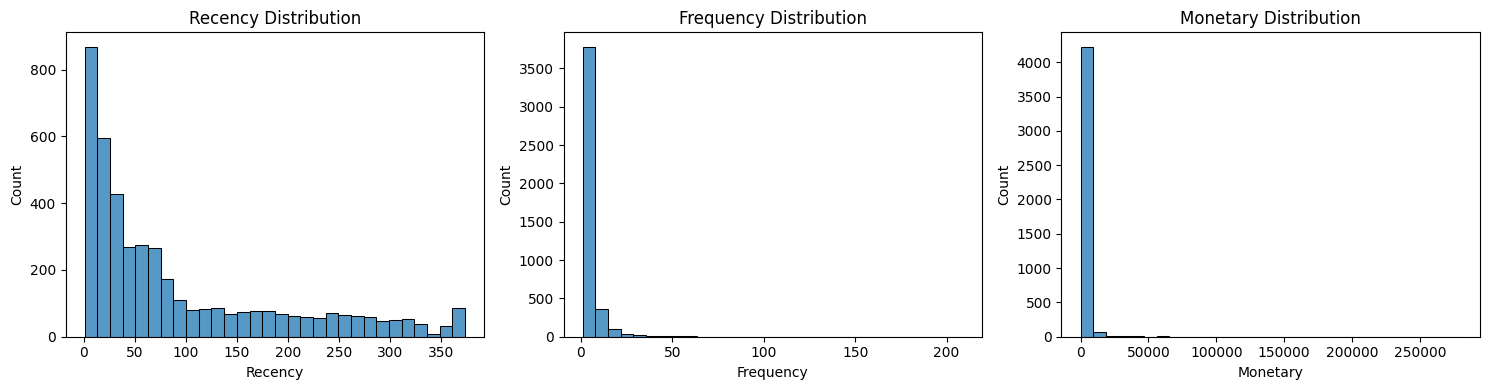

In [93]:
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
sns.histplot(rfm['Recency'], bins=30)
plt.title("Recency Distribution")

plt.subplot(1, 3, 2)
sns.histplot(rfm['Frequency'], bins=30)
plt.title("Frequency Distribution")

plt.subplot(1, 3, 3)
sns.histplot(rfm['Monetary'], bins=30)
plt.title("Monetary Distribution")

plt.tight_layout()
plt.show()

In [94]:
from sklearn.preprocessing import StandardScaler

In [95]:
X = rfm[['Recency', 'Frequency', 'Monetary']]

X.head()

,Recency,Frequency,Monetary
0,326,1,77183.60
1,2,7,4310.00
2,75,4,1797.24
3,19,1,1757.55
4,310,1,334.40


In [96]:
X_log = np.log1p(X)

X_log.head()

,Recency,Frequency,Monetary
0,5.789960,0.693147,11.253955
1,1.098612,2.079442,8.368925
2,4.330733,1.609438,7.494564
3,2.995732,0.693147,7.472245
4,5.739793,0.693147,5.815324


In [97]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_log)

print("Scaled Data Shape:", X_scaled.shape)
print(X_scaled[:5])

Scaled Data Shape: (4338, 3)
[[ 1.46199281 -0.95521426  3.7077163 ]
 [-2.03873442  1.07442519  1.41490344]
 [ 0.37310424  0.38630445  0.72002428]
 [-0.62308592 -0.95521426  0.70228691]
 [ 1.42455753 -0.95521426 -0.61451388]]


In [98]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

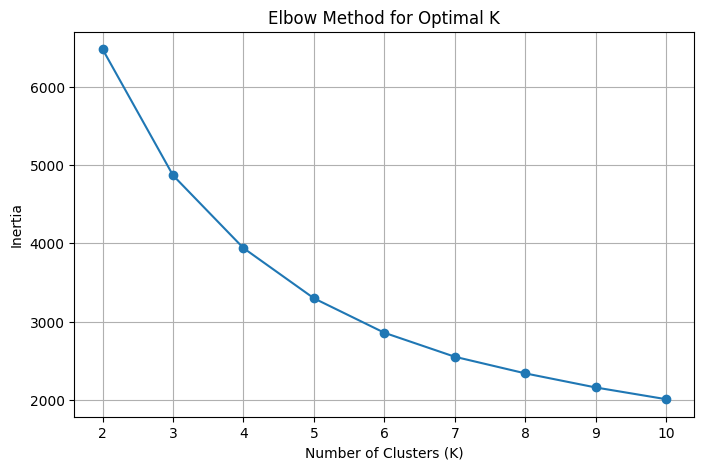

In [99]:
inertia = []

K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker='o')

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal K")
plt.grid(True)
plt.show()

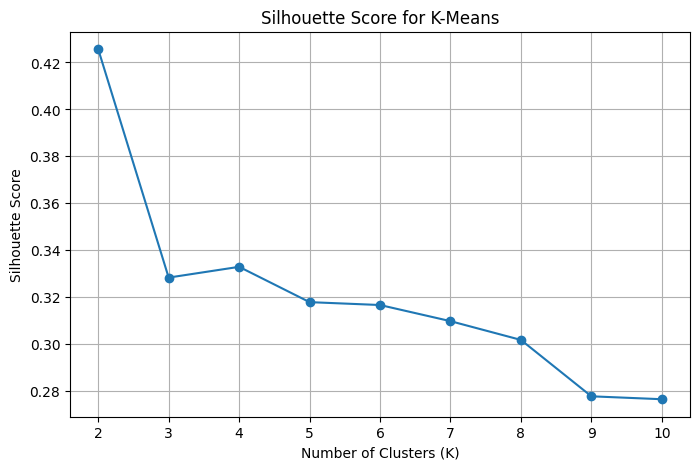

Best K: 2


In [100]:
scores = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=min(2000, len(X_scaled)),
        random_state=42
    )

    scores.append(score)

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), scores, marker='o')

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for K-Means")
plt.grid(True)
plt.show()

best_k = list(range(2, 11))[np.argmax(scores)]

print("Best K:", best_k)

In [101]:
kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

rfm['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)

print("K-Means Clustering Completed!")

print(rfm['KMeans_Cluster'].value_counts().sort_index())

rfm.head()

K-Means Clustering Completed!
KMeans_Cluster
0    2672
1    1666
Name: count, dtype: int64


,CustomerID,Recency,Frequency,Monetary,KMeans_Cluster
0,12346.0,326,1,77183.60,1
1,12347.0,2,7,4310.00,1
2,12348.0,75,4,1797.24,1
3,12349.0,19,1,1757.55,0
4,12350.0,310,1,334.40,0


In [102]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

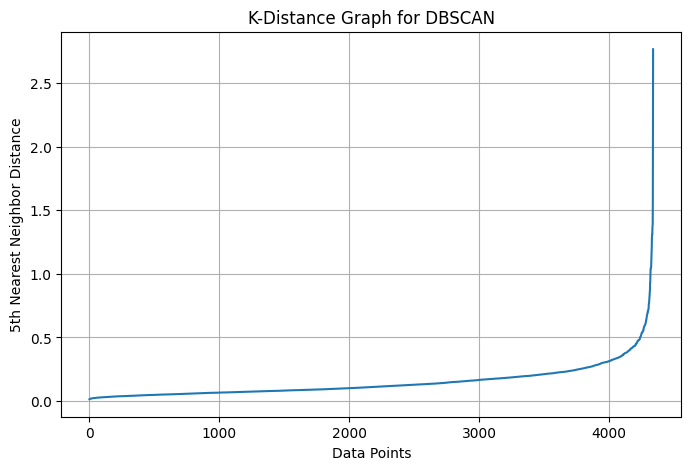

In [103]:
neighbors = NearestNeighbors(n_neighbors=5)

neighbors_fit = neighbors.fit(X_scaled)

distances, indices = neighbors_fit.kneighbors(X_scaled)

distances = np.sort(distances[:, 4])

plt.figure(figsize=(8, 5))
plt.plot(distances)

plt.xlabel("Data Points")
plt.ylabel("5th Nearest Neighbor Distance")
plt.title("K-Distance Graph for DBSCAN")
plt.grid(True)
plt.show()

In [104]:
dbscan = DBSCAN(
    eps=0.5,
    min_samples=5
)

rfm['DBSCAN_Cluster'] = dbscan.fit_predict(X_scaled)

print("DBSCAN Clustering Completed!")
print(rfm['DBSCAN_Cluster'].value_counts().sort_index())

DBSCAN Clustering Completed!
DBSCAN_Cluster
-1      62
 0    2791
 1    1485
Name: count, dtype: int64


In [105]:
labels = rfm['DBSCAN_Cluster']

n_clusters = len(set(labels)) - (1 if -1 in labels.values else 0)

n_noise = (labels == -1).sum()

print("Number of Clusters:", n_clusters)
print("Number of Noise Points:", n_noise)

Number of Clusters: 2
Number of Noise Points: 62


In [106]:
comparison = pd.DataFrame({
    'Algorithm': ['K-Means', 'DBSCAN'],
    'Number of Clusters': [
        rfm['KMeans_Cluster'].nunique(),
        n_clusters
    ],
    'Noise Points': [
        0,
        n_noise
    ]
})

comparison

,Algorithm,Number of Clusters,Noise Points
0,K-Means,2,0
1,DBSCAN,2,62


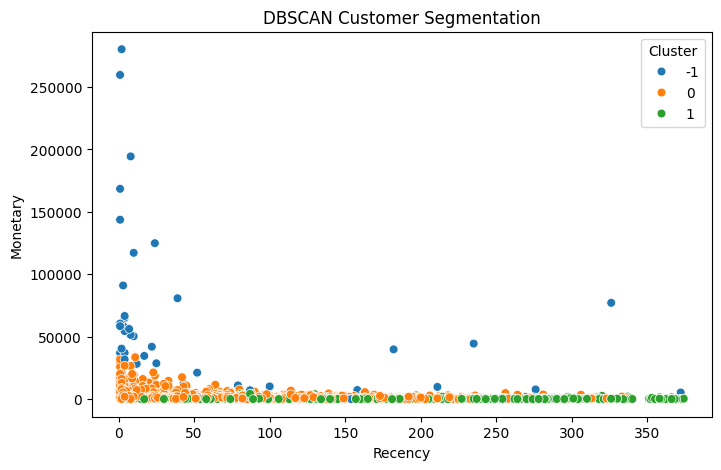

In [107]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=rfm['Recency'],
    y=rfm['Monetary'],
    hue=rfm['DBSCAN_Cluster'].astype(str),
    palette='tab10',
    s=40
)

plt.xlabel("Recency")
plt.ylabel("Monetary")
plt.title("DBSCAN Customer Segmentation")
plt.legend(title="Cluster")
plt.show()

In [108]:
from sklearn.decomposition import PCA

In [109]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Original Shape:", X_scaled.shape)
print("PCA Shape:", X_pca.shape)

Original Shape: (4338, 3)
PCA Shape: (4338, 2)


In [110]:
print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("Total Explained Variance:",
      pca.explained_variance_ratio_.sum())

Explained Variance Ratio:
[0.75078634 0.18786648]
Total Explained Variance: 0.9386528181989533


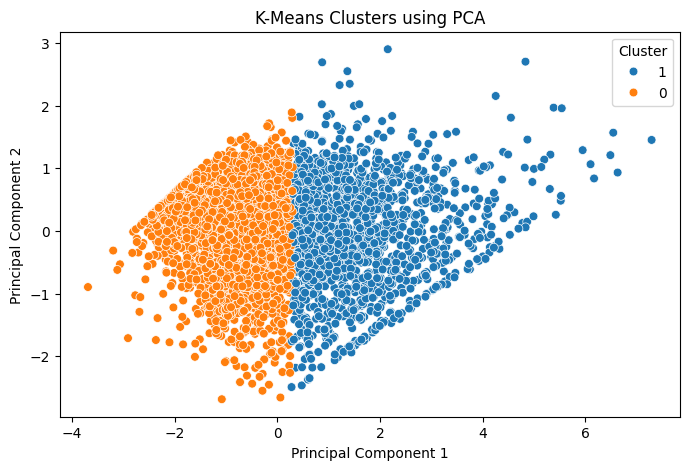

In [111]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=rfm['KMeans_Cluster'].astype(str),
    palette='tab10',
    s=40
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clusters using PCA")
plt.legend(title="Cluster")
plt.show()

In [112]:
from sklearn.manifold import TSNE

In [113]:
tsne = TSNE(
    n_components=2,
    perplexity=30,
    random_state=42,
    init='pca',
    learning_rate='auto'
)

X_tsne = tsne.fit_transform(X_scaled)

print("t-SNE Shape:", X_tsne.shape)

t-SNE Shape: (4338, 2)


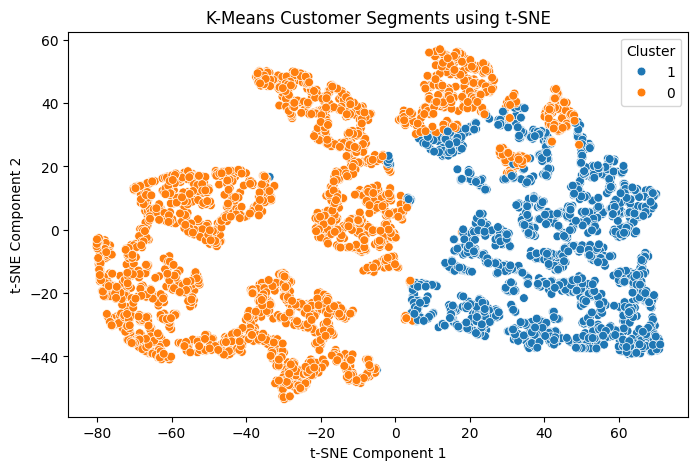

In [114]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=X_tsne[:, 0],
    y=X_tsne[:, 1],
    hue=rfm['KMeans_Cluster'].astype(str),
    palette='tab10',
    s=40
)

plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.title("K-Means Customer Segments using t-SNE")
plt.legend(title="Cluster")
plt.show()

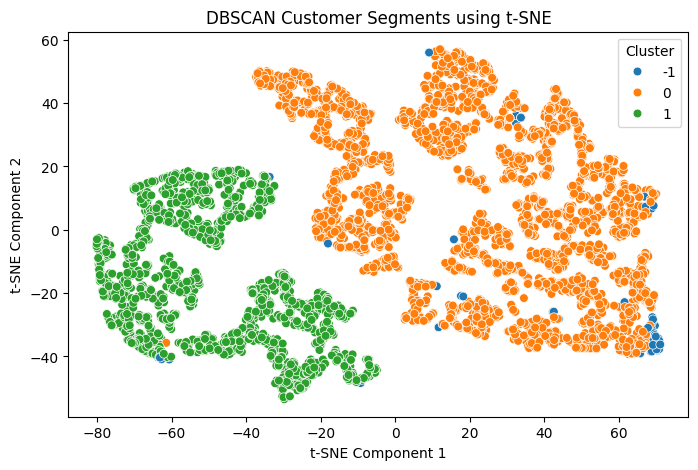

In [115]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=X_tsne[:, 0],
    y=X_tsne[:, 1],
    hue=rfm['DBSCAN_Cluster'].astype(str),
    palette='tab10',
    s=40
)

plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.title("DBSCAN Customer Segments using t-SNE")
plt.legend(title="Cluster")
plt.show()

In [116]:
cluster_summary = rfm.groupby('KMeans_Cluster').agg(
    Customers=('CustomerID', 'count'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean')
)

print(cluster_summary.round(2))

                Customers  Avg_Recency  Avg_Frequency  Avg_Monetary
KMeans_Cluster                                                     
0                    2672       134.09           1.67        495.59
1                    1666        25.89           8.44       4539.60


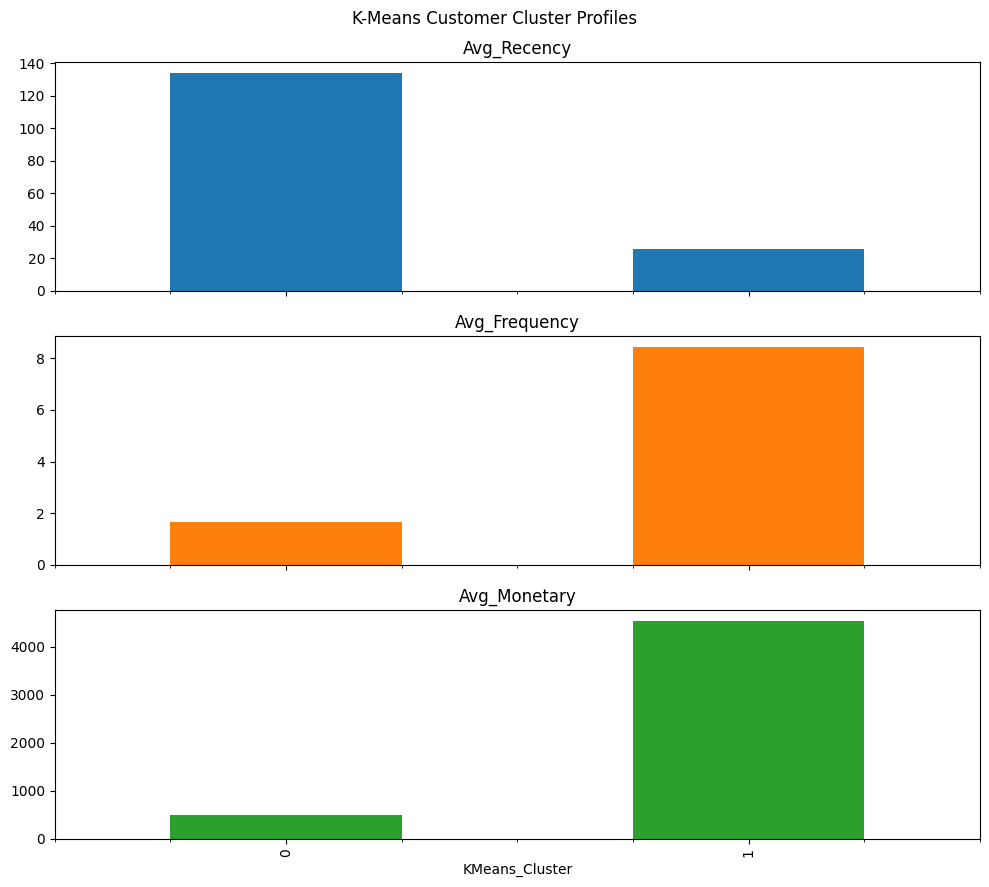

In [117]:
cluster_summary[
    ['Avg_Recency', 'Avg_Frequency', 'Avg_Monetary']
].plot(
    kind='bar',
    subplots=True,
    figsize=(10, 9),
    layout=(3, 1),
    legend=False
)

plt.suptitle("K-Means Customer Cluster Profiles")
plt.tight_layout()
plt.show()

In [118]:
for cluster, row in cluster_summary.iterrows():

    print(f"\nCluster {cluster}")
    print("Customers:", int(row['Customers']))

    if (row['Avg_Frequency'] >= rfm['Frequency'].median()
        and row['Avg_Monetary'] >= rfm['Monetary'].median()
        and row['Avg_Recency'] <= rfm['Recency'].median()):

        print("Persona: Loyal / High-Value Customers")
        print("Strategy: VIP rewards and loyalty offers")

    elif row['Avg_Recency'] > rfm['Recency'].median():

        print("Persona: At-Risk Customers")
        print("Strategy: Re-engagement campaigns")

    else:
        print("Persona: Regular / Developing Customers")
        print("Strategy: Personalized product recommendations")


Cluster 0
Customers: 2672
Persona: At-Risk Customers
Strategy: Re-engagement campaigns

Cluster 1
Customers: 1666
Persona: Loyal / High-Value Customers
Strategy: VIP rewards and loyalty offers


In [119]:
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

In [120]:
kmeans_labels = rfm['KMeans_Cluster'].values

kmeans_silhouette = silhouette_score(
    X_scaled, kmeans_labels
)

kmeans_db = davies_bouldin_score(
    X_scaled, kmeans_labels
)

kmeans_ch = calinski_harabasz_score(
    X_scaled, kmeans_labels
)

print("K-Means Evaluation Results")
print("Silhouette Score:", round(kmeans_silhouette, 4))
print("Davies-Bouldin Index:", round(kmeans_db, 4))
print("Calinski-Harabasz Score:", round(kmeans_ch, 4))

K-Means Evaluation Results
Silhouette Score: 0.4328
Davies-Bouldin Index: 0.8925
Calinski-Harabasz Score: 4367.3231


In [121]:
dbscan_labels = rfm['DBSCAN_Cluster'].values

mask = dbscan_labels != -1

X_dbscan = X_scaled[mask]
labels_dbscan = dbscan_labels[mask]

if 2 <= len(set(labels_dbscan)) < len(labels_dbscan):

    dbscan_silhouette = silhouette_score(
        X_dbscan, labels_dbscan
    )

    dbscan_db = davies_bouldin_score(
        X_dbscan, labels_dbscan
    )

    dbscan_ch = calinski_harabasz_score(
        X_dbscan, labels_dbscan
    )

    print("DBSCAN Evaluation Results")
    print("Silhouette Score:", round(dbscan_silhouette, 4))
    print("Davies-Bouldin Index:", round(dbscan_db, 4))
    print("Calinski-Harabasz Score:", round(dbscan_ch, 4))

else:
    dbscan_silhouette = float('nan')
    dbscan_db = float('nan')
    dbscan_ch = float('nan')

    print("DBSCAN has fewer than 2 valid clusters.")
    print("Evaluation metrics cannot be calculated.")

DBSCAN Evaluation Results
Silhouette Score: 0.293
Davies-Bouldin Index: 1.0636
Calinski-Harabasz Score: 2390.1964


In [122]:
results = pd.DataFrame({
    'Algorithm': ['K-Means', 'DBSCAN'],
    'Silhouette Score': [
        kmeans_silhouette,
        dbscan_silhouette
    ],
    'Davies-Bouldin Index': [
        kmeans_db,
        dbscan_db
    ],
    'Calinski-Harabasz Score': [
        kmeans_ch,
        dbscan_ch
    ]
})

results.round(4)

,Algorithm,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
0,K-Means,0.4328,0.8925,4367.3231
1,DBSCAN,0.2930,1.0636,2390.1964


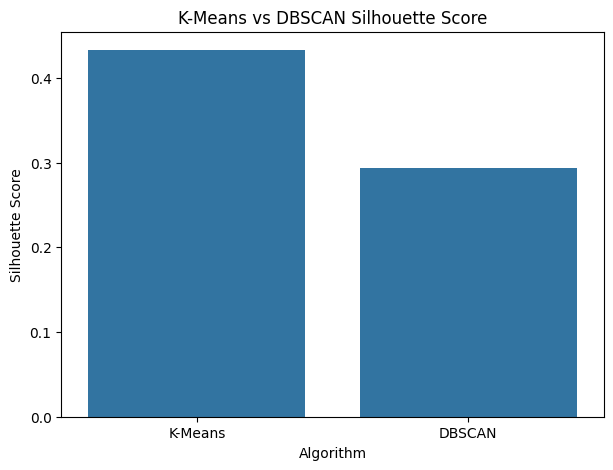

In [123]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=results,
    x='Algorithm',
    y='Silhouette Score'
)

plt.title("K-Means vs DBSCAN Silhouette Score")
plt.ylabel("Silhouette Score")
plt.show()

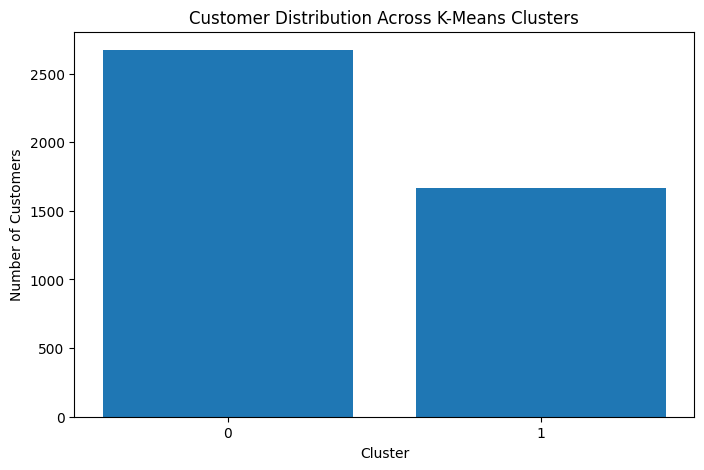

In [124]:
cluster_counts = rfm['KMeans_Cluster'].value_counts().sort_index()

plt.figure(figsize=(8, 5))

plt.bar(
    cluster_counts.index.astype(str),
    cluster_counts.values
)

plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.title("Customer Distribution Across K-Means Clusters")
plt.show()

In [125]:
rfm.to_csv(
    "customer_segments.csv",
    index=False
)

print("Customer Segments Saved Successfully!")

Customer Segments Saved Successfully!


In [126]:
results.to_csv(
    "clustering_evaluation.csv",
    index=False
)

print("Evaluation Results Saved Successfully!")

Evaluation Results Saved Successfully!


In [127]:
print("E-COMMERCE CUSTOMER SEGMENTATION")
print("--------------------------------")

print("Total Customers:", len(rfm))

print(
    "K-Means Clusters:",
    rfm['KMeans_Cluster'].nunique()
)

print(
    "DBSCAN Clusters:",
    len(set(dbscan_labels) - {-1})
)

print(
    "DBSCAN Noise Points:",
    (dbscan_labels == -1).sum()
)

print(
    "PCA Explained Variance:",
    round(pca.explained_variance_ratio_.sum(), 4)
)

print("\nProject Completed Successfully!")

E-COMMERCE CUSTOMER SEGMENTATION
--------------------------------
Total Customers: 4338
K-Means Clusters: 2
DBSCAN Clusters: 2
DBSCAN Noise Points: 62
PCA Explained Variance: 0.9387

Project Completed Successfully!


## Conclusion

  In this case study, we performed customer segmentation using an e-commerce transaction dataset.

  We applied data preprocessing and RFM analysis to understand customer purchasing behaviour. K-Means and DBSCAN clustering algorithms were used to identify customer groups.

  StandardScaler was used for feature scaling, while PCA and t-SNE helped visualize customer segments in two dimensions.

  Clustering evaluation metrics were calculated to assess the quality of the resulting groups. We also analyzed cluster-level purchasing behaviour to suggest marketing personas and targeted marketing strategies.

  The analysis demonstrates how unsupervised machine learning can support customer segmentation and marketing decisions.